# Combining B_036, B_039 and B_042 
using numpyro MCMC inference instead of pyros VI

In [26]:
import json
from pathlib import Path
import sys

sys.argv = [""]
import numpyro
numpyro.set_host_device_count(4)
import jax
import jax.numpy as jnp
import diffrax as dfx
# jax.config.update("jax_disable_jit",True)
jax.local_device_count()

import numpy as np
import matplotlib.pyplot as plt
import arviz as az
import xarray
import ICIW_Plots
import tqdm

plt.style.use("ICIWstyle")
plt.rcParams["figure.dpi"] = 600
plt.rcParams["font.size"] = 8

In [27]:
from HSA_Cam_B_039_numpyro import kl_divergence_between_models
from HSA_Mo_B_011_numpyro import (
    kinetics_model,
    predict,
    generate_synthetic_data,
    calculate_partial_pressures,
    validate_against_holdout,
    sample_prior,
    TRUE_PARAMS,
)

In [28]:
ov = [
    {
        "ID": "B_036",
        "run_name": "chivalrous-infographic",
        "dir": Path("data/chivalrous-infographic"),
        "DOE": "Koschany DOE",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "idatas": None,
        "proposals": None,
        "r_obs": None,
        "valdatas": None,
        "RMSEs": None,
    },
    {
        "ID": "B_039",
        "run_name": "agitated-health",
        "dir": Path("data/agitated-health"),
        "DOE": "paramEKLD DOE",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "idatas": None,
        "proposals": None,
        "r_obs": None,
        "valdatas": None,
        "RMSEs": None,
    },
    {
        "ID": "B_042",
        "run_name": "eternal-rock",
        "dir": Path("data/eternal-rock"),
        "DOE": "predEKLD DOE",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "idatas": None,
        "proposals": None,
        "r_obs": None,
        "valdatas": None,
        "RMSEs": None,
    },
]

In [29]:
def load_files(ov_dict):
    sum_file = ov_dict["dir"] / f"experiment_summary_{ov_dict['run_name']}.json"
    trace_files = sorted(ov_dict["dir"].glob(f"trace_*.nc"))
    test_data = xarray.open_dataset(ov_dict["holdout_data"])
    idatas = []
    valdatas = []
    paramEKLDS = []
    paramEKLDS_to_prior = []
    for i, trace_file in enumerate(tqdm.tqdm(trace_files)):
        idata = az.from_netcdf(trace_file)
        if i == 0:
            idata.add_groups({"prior": sample_prior(4000).prior})
        else:
            idata.add_groups({"prior": idatas[i - 1].posterior})
        idatas.append(idata)
        valdata = validate_against_holdout(
            idata,
            test_data,
            num_samples=1000,
        )
        paramEKLD = kl_divergence_between_models(
                idata_new=idata,
                idata_old=idata,
                key_new="posterior",
                key_old="prior",
                var_names=[
                    "k0",
                    "Ea_k",
                    "A_oh",
                    "dH_oh",
                    "A_h2",
                    "dH_h2",
                    "A_mix",
                    "dH_mix",
                    "sigma_r",
                ],
            ).sum()
        paramEKLD_to_prior = kl_divergence_between_models(
                idata_new=idata,
                idata_old=idatas[0],
                key_new="posterior",
                key_old="prior",
                var_names=[
                    "k0",
                    "Ea_k",
                    "A_oh",
                    "dH_oh",
                    "A_h2",
                    "dH_h2",
                    "A_mix",
                    "dH_mix",
                    "sigma_r",
                ],
            ).sum()
        paramEKLDS.append(paramEKLD)
        paramEKLDS_to_prior.append(paramEKLD_to_prior)
        valdatas.append(valdata)
    ov_dict["idatas"] = idatas
    ov_dict["valdatas"] = valdatas
    ov_dict["paramEKLDS"] = paramEKLDS
    ov_dict["paramEKLDS_to_prior"] = paramEKLDS_to_prior
    with open(sum_file, "r") as f:
        exp_summary = json.load(f)
    ov_dict["proposals"] = np.array(exp_summary["trials"][-1]["observed"]["x"])
    ov_dict["r_obs"] = np.array(exp_summary["trials"][-1]["observed"]["y"])

In [30]:
for ov_dict in ov:
    load_files(ov_dict)
    print(ov_dict["r_obs"])

  0%|          | 0/64 [00:00<?, ?it/s]/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically

/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically

  2%|▏         | 1/64 [00:01<01:50,  1.76s/it]/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically

/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically

  3%|▎         | 2/64 [00:02<01:22,  1.34s/it]/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically

/home/hann

[[1.95435732e-05]
 [3.54373697e-05]
 [5.83814908e-05]
 [1.48688458e-04]
 [2.49709483e-05]
 [4.49895051e-05]
 [6.36128025e-05]
 [2.09380232e-04]
 [2.38393695e-05]
 [4.30005275e-05]
 [6.38878337e-05]
 [1.93399159e-04]
 [2.84745274e-05]
 [4.83323929e-05]
 [7.36608490e-05]
 [2.14043102e-04]
 [2.45979027e-05]
 [4.17338633e-05]
 [5.92950746e-05]
 [1.97556350e-04]
 [1.81384457e-05]
 [2.87181301e-05]
 [4.45275036e-05]
 [1.51173095e-04]
 [1.82925924e-05]
 [3.71592614e-05]
 [4.87889629e-05]
 [1.44094593e-04]
 [7.83500298e-07]
 [3.02032095e-06]
 [1.03744815e-05]
 [7.59320926e-07]
 [2.54099814e-06]
 [1.07681271e-05]
 [7.41266831e-07]
 [2.48163246e-06]
 [1.01934893e-05]
 [6.99614986e-07]
 [2.27614646e-06]
 [8.37559219e-06]
 [2.88066240e-05]
 [5.31033875e-05]
 [8.57258347e-05]
 [2.33002123e-04]
 [2.62299018e-05]
 [3.93789378e-05]
 [7.76413872e-05]
 [2.18236280e-04]
 [1.94316872e-05]
 [2.98858668e-05]
 [5.47566779e-05]
 [1.36012939e-04]
 [2.60466149e-05]
 [5.11972612e-05]
 [7.74687942e-05]
 [1.809247

  0%|          | 0/32 [00:00<?, ?it/s]/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically

/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically

  3%|▎         | 1/32 [00:01<00:46,  1.50s/it]/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically

/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically

  6%|▋         | 2/32 [00:02<00:35,  1.19s/it]/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically

/home/hann

[[7.54950349e-07]
 [1.76078247e-04]
 [7.83488867e-05]
 [2.62141293e-06]
 [9.66572225e-06]
 [2.32854203e-04]
 [1.05826416e-07]
 [1.02931401e-04]
 [3.88796224e-07]
 [1.41701472e-04]
 [7.86922328e-07]
 [3.08492672e-05]
 [3.32577329e-04]
 [3.63180163e-07]
 [4.65235316e-05]
 [3.30496334e-07]
 [7.09769495e-07]
 [1.32725283e-04]
 [2.48478551e-04]
 [2.55892694e-04]
 [3.82377242e-04]
 [3.86072752e-05]
 [2.34228821e-04]
 [3.39429789e-07]
 [1.03550792e-06]
 [1.97061837e-07]
 [1.77745333e-05]
 [1.57478453e-07]
 [1.71668819e-06]
 [7.75841613e-07]
 [2.54212704e-04]
 [2.96302478e-05]]


  0%|          | 0/32 [00:00<?, ?it/s]/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically

/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically

  3%|▎         | 1/32 [00:01<00:45,  1.48s/it]/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically

/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically

  6%|▋         | 2/32 [00:02<00:34,  1.16s/it]/home/hannes/envs/numpyroenv/lib/python3.12/site-packages/arviz/data/inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically

/home/hann

[[7.75984347e-07]
 [9.54363713e-05]
 [1.09246980e-06]
 [4.44414109e-05]
 [8.67387644e-06]
 [4.03154758e-07]
 [3.67531291e-04]
 [2.62139074e-04]
 [4.48418717e-07]
 [1.00394172e-04]
 [4.50014659e-06]
 [3.23687040e-04]
 [5.69915528e-07]
 [4.34196554e-04]
 [2.88931682e-04]
 [1.91693289e-07]
 [1.12023247e-06]
 [5.86040244e-07]
 [3.74293195e-05]
 [2.45076255e-04]
 [9.61330784e-07]
 [2.55089399e-04]
 [3.77153119e-05]
 [1.89625018e-04]
 [3.96474661e-07]
 [1.63304547e-04]
 [5.78498486e-07]
 [1.56900896e-07]
 [5.11403698e-07]
 [4.95536486e-04]
 [4.63696815e-05]
 [1.26311534e-07]]


In [31]:
def bRMSE(postdata, var_name):
    true = postdata.observed_data[var_name].values
    pred = postdata.posterior_predictive[var_name].values
    res = true - pred
    rmse_vals = np.sqrt(np.mean(res**2, axis=2)).squeeze()
    return rmse_vals


def calculate_RMSEs(ov_dict):
    ov_dict["RMSEs"] = None
    for valdata in ov_dict["valdatas"]:
        rmse_da = bRMSE(valdata, "r_pred")
        if ov_dict["RMSEs"] is None:
            ov_dict["RMSEs"] = [rmse_da]
        else:
            ov_dict["RMSEs"].append(rmse_da)
    ov_dict["RMSEs"] = np.array(ov_dict["RMSEs"])

In [32]:
for ov_dict in ov:
    calculate_RMSEs(ov_dict)

### Predictive accuracy

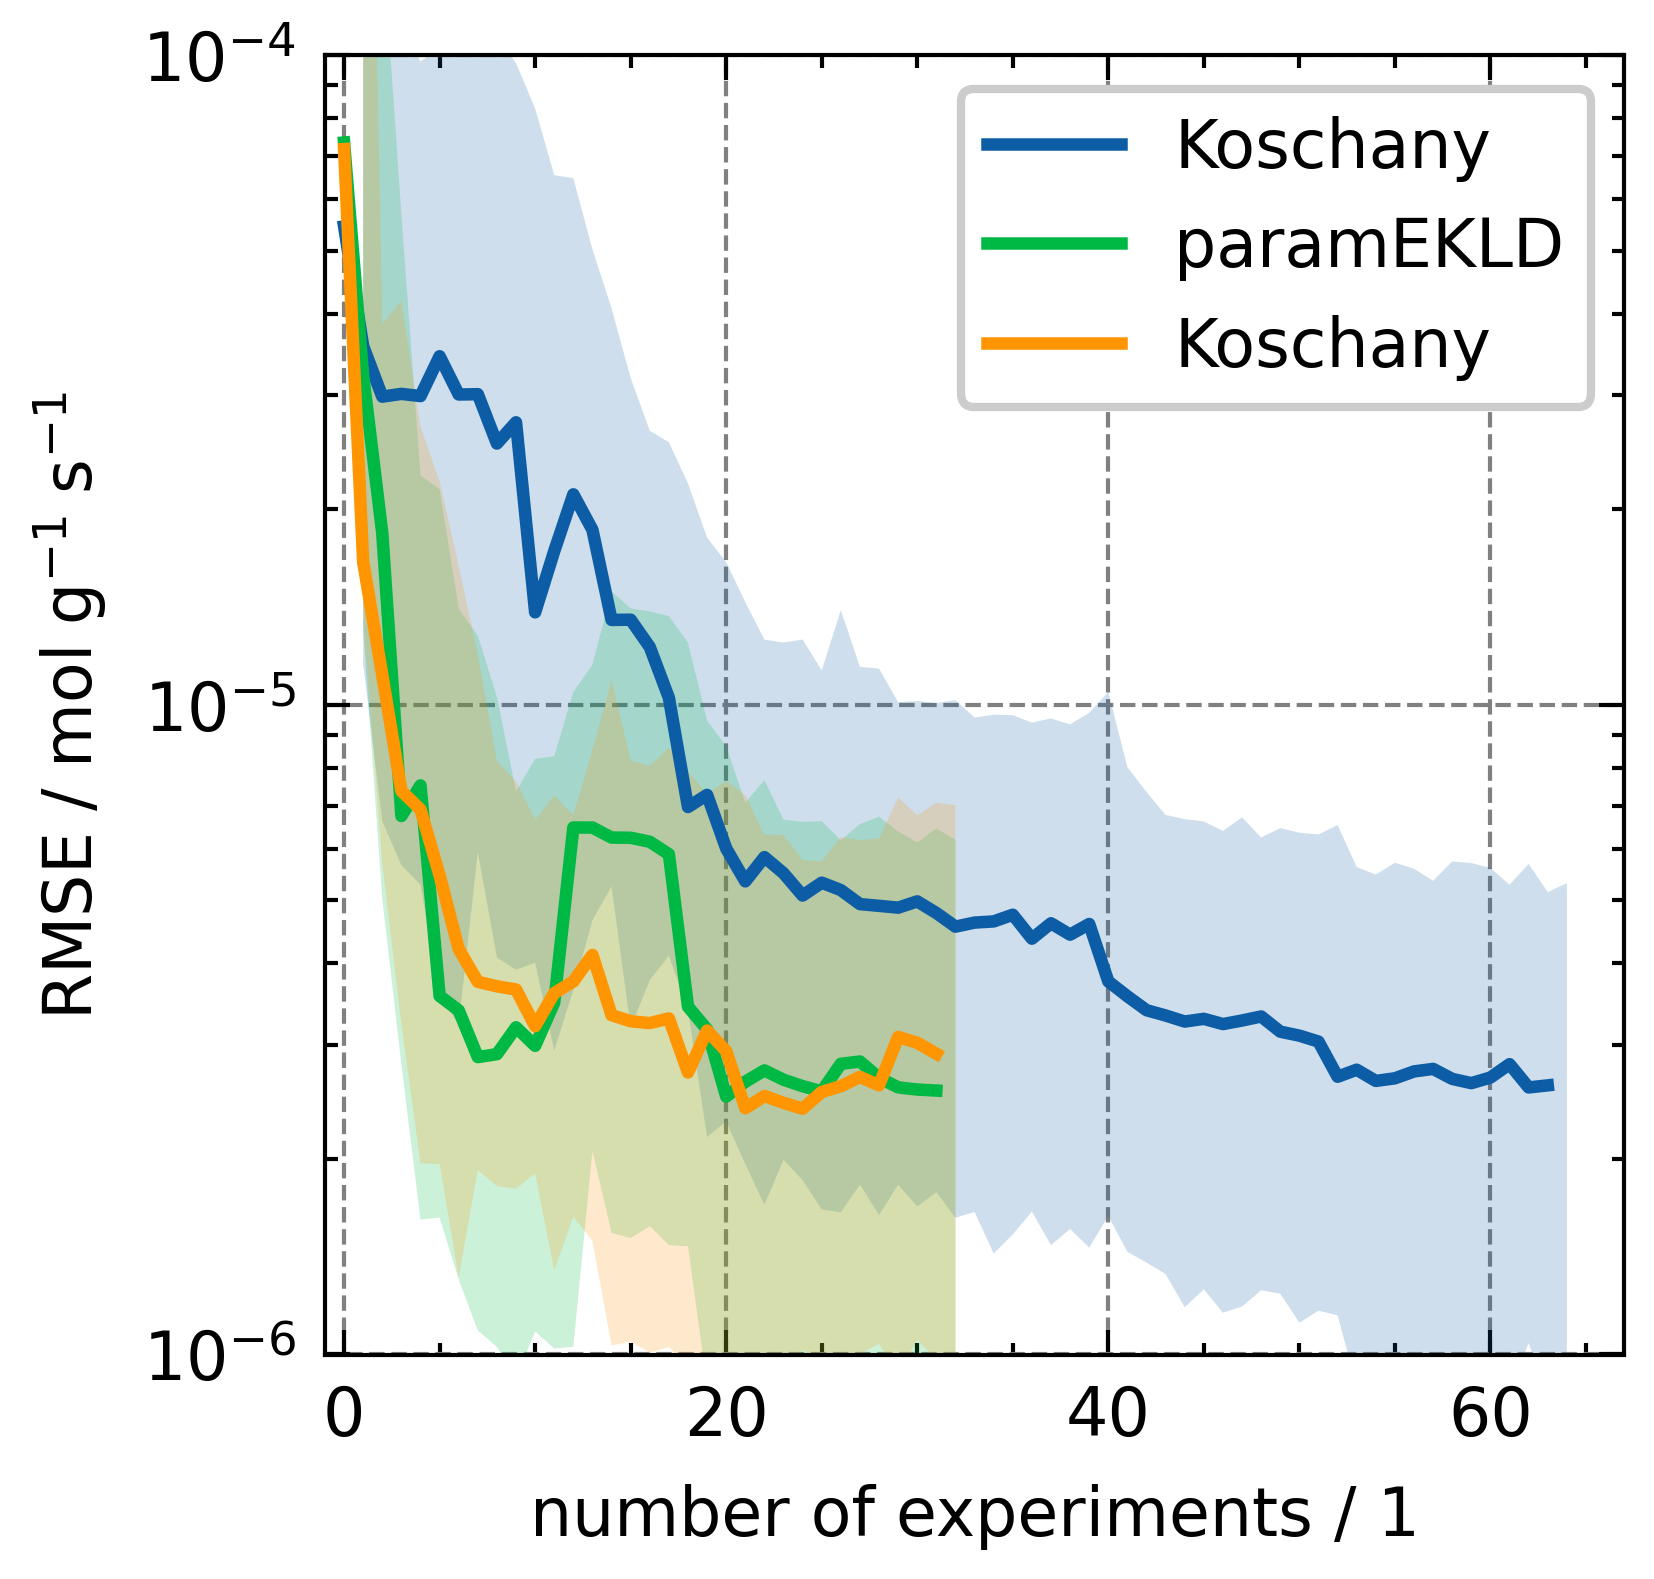

In [33]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"RMSE / $\mathrm{mol}\;\mathrm{g}^{-1}\;\mathrm{s}^{-1}$",
    yscale="log",
    ylim=(1e-6, 1e-4),
    xlim=(-1, 67),
)

for ov_dict in ov:
    if ov_dict["DOE"] == "predEKLD DOE":
        label = "predEKLD"
    if ov_dict["DOE"] == "paramEKLD DOE":
        label = "paramEKLD"
    else:
        label = "Koschany"
    ax.plot(
        np.median(ov_dict["RMSEs"], axis=1),
        label=label,
    )
    ax.fill_between(
        np.arange(1, len(ov_dict["RMSEs"]) + 1),
        np.quantile(ov_dict["RMSEs"], 0.025, axis=1),
        np.quantile(ov_dict["RMSEs"], 0.975, axis=1),
        alpha=0.2,
        ls="--",
        # edgecolor="gray",
    )
    ax.legend(frameon=True)

plt.savefig("B_042_RMSE.png", dpi=600, bbox_inches="tight")

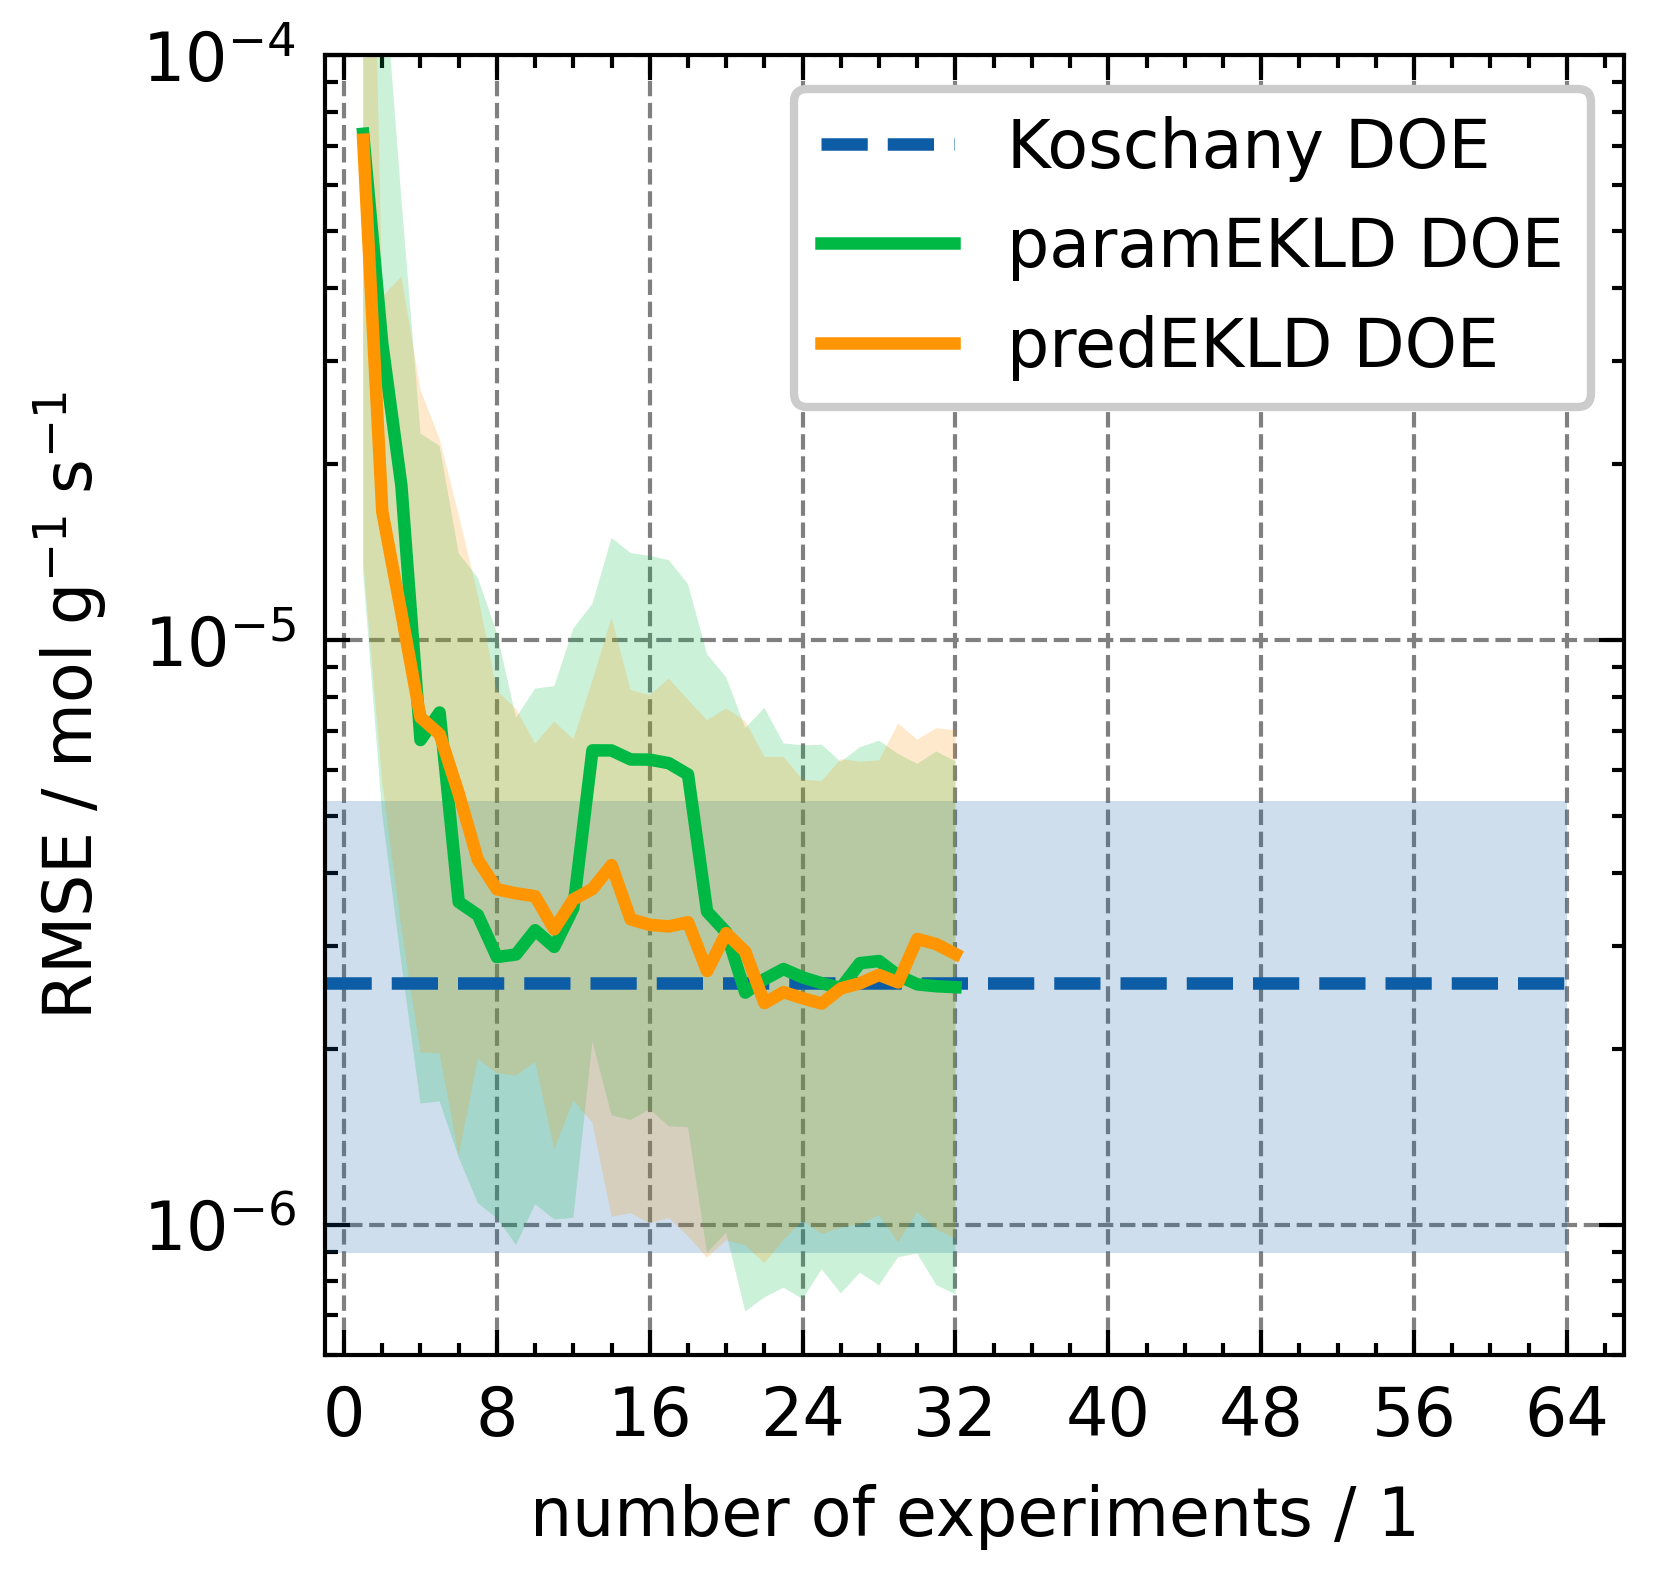

In [34]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"RMSE / $\mathrm{mol}\;\mathrm{g}^{-1}\;\mathrm{s}^{-1}$",
    yscale="log",
    ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0,8,16,24,32,40,48,56,64],
)

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
for i, ov_dict in enumerate(ov):
    if ov_dict["DOE"] == "Koschany DOE":
        ax.hlines(
            np.median(ov_dict["RMSEs"], axis=1)[-1],
            xmin=-1,
            xmax=64,
            label=ov_dict["DOE"],
            ls="--",
            color=colors[i],
        )
        ax.fill_between(
            np.arange(-1, len(ov_dict["RMSEs"]) + 1),
            np.quantile(ov_dict["RMSEs"], 0.025, axis=1)[-1],
            np.quantile(ov_dict["RMSEs"], 0.975, axis=1)[-1],
            alpha=0.2,
            #ls="--",
            facecolor=colors[i],
            # edgecolor="gray",
        )
        continue
    ax.plot(
        np.arange(1, len(ov_dict["RMSEs"]) + 1),
        np.median(ov_dict["RMSEs"], axis=1),
        #"o--",
        #ms=4,
        #lw=1,
        label=ov_dict["DOE"],
        color=colors[i],
    )
    ax.fill_between(
        np.arange(1, len(ov_dict["RMSEs"]) + 1),
        np.quantile(ov_dict["RMSEs"], 0.025, axis=1),
        np.quantile(ov_dict["RMSEs"], 0.975, axis=1),
        alpha=0.2,
        #ls="--",
        facecolor=colors[i],
        # edgecolor="gray",
    )
    ax.legend(frameon=True)

#plt.savefig("B_042_RMSE.png", dpi=600, bbox_inches="tight")

### Information Gain

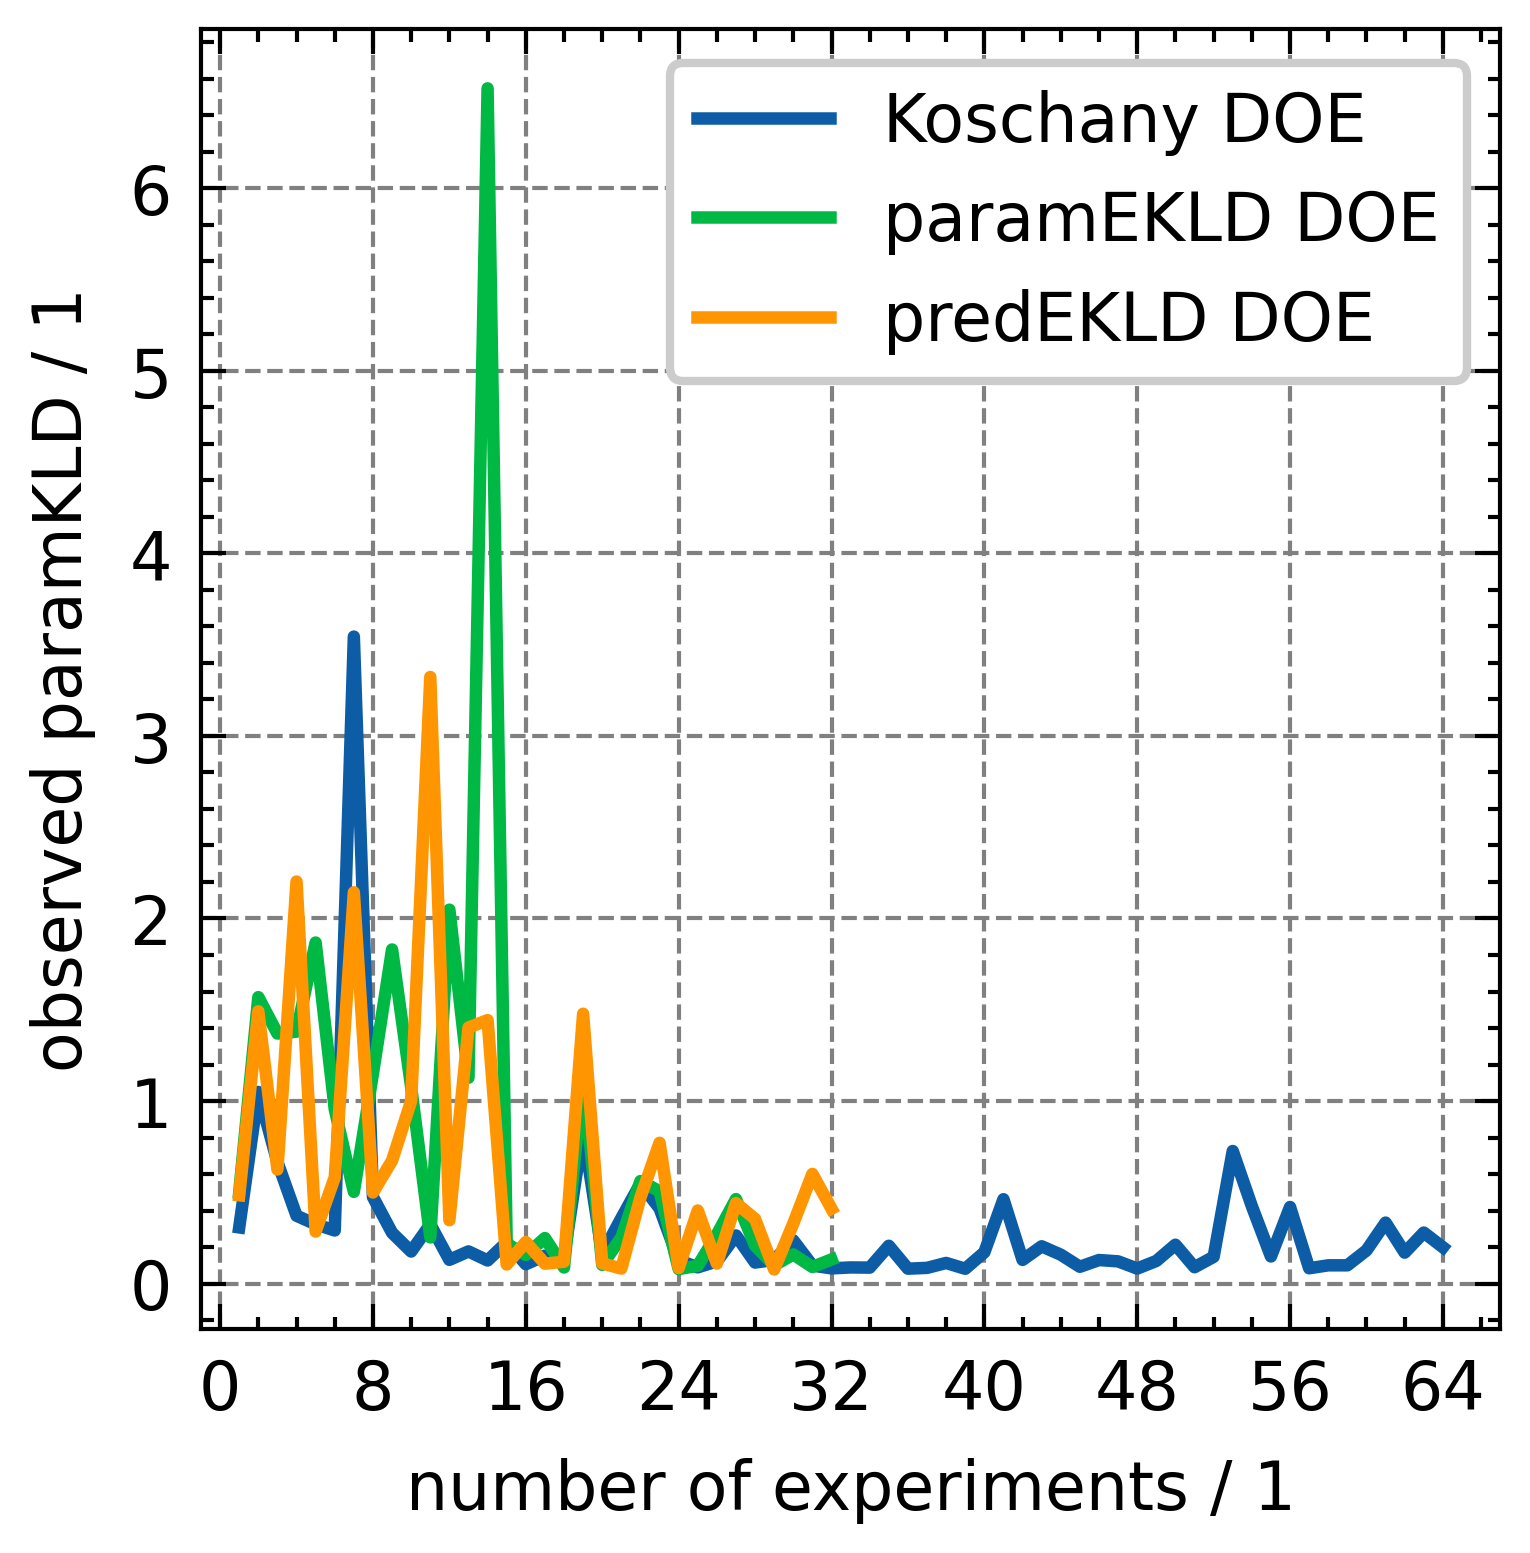

In [35]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel="observed paramKLD / 1",
    #ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0,8,16,24,32,40,48,56,64],
)
for i, ov_dict in enumerate(ov):
    ax.plot(
        np.arange(len(ov_dict["paramEKLDS"])) + 1,
        ov_dict["paramEKLDS"], 
        label=ov_dict["DOE"],
    )
    ax.legend()

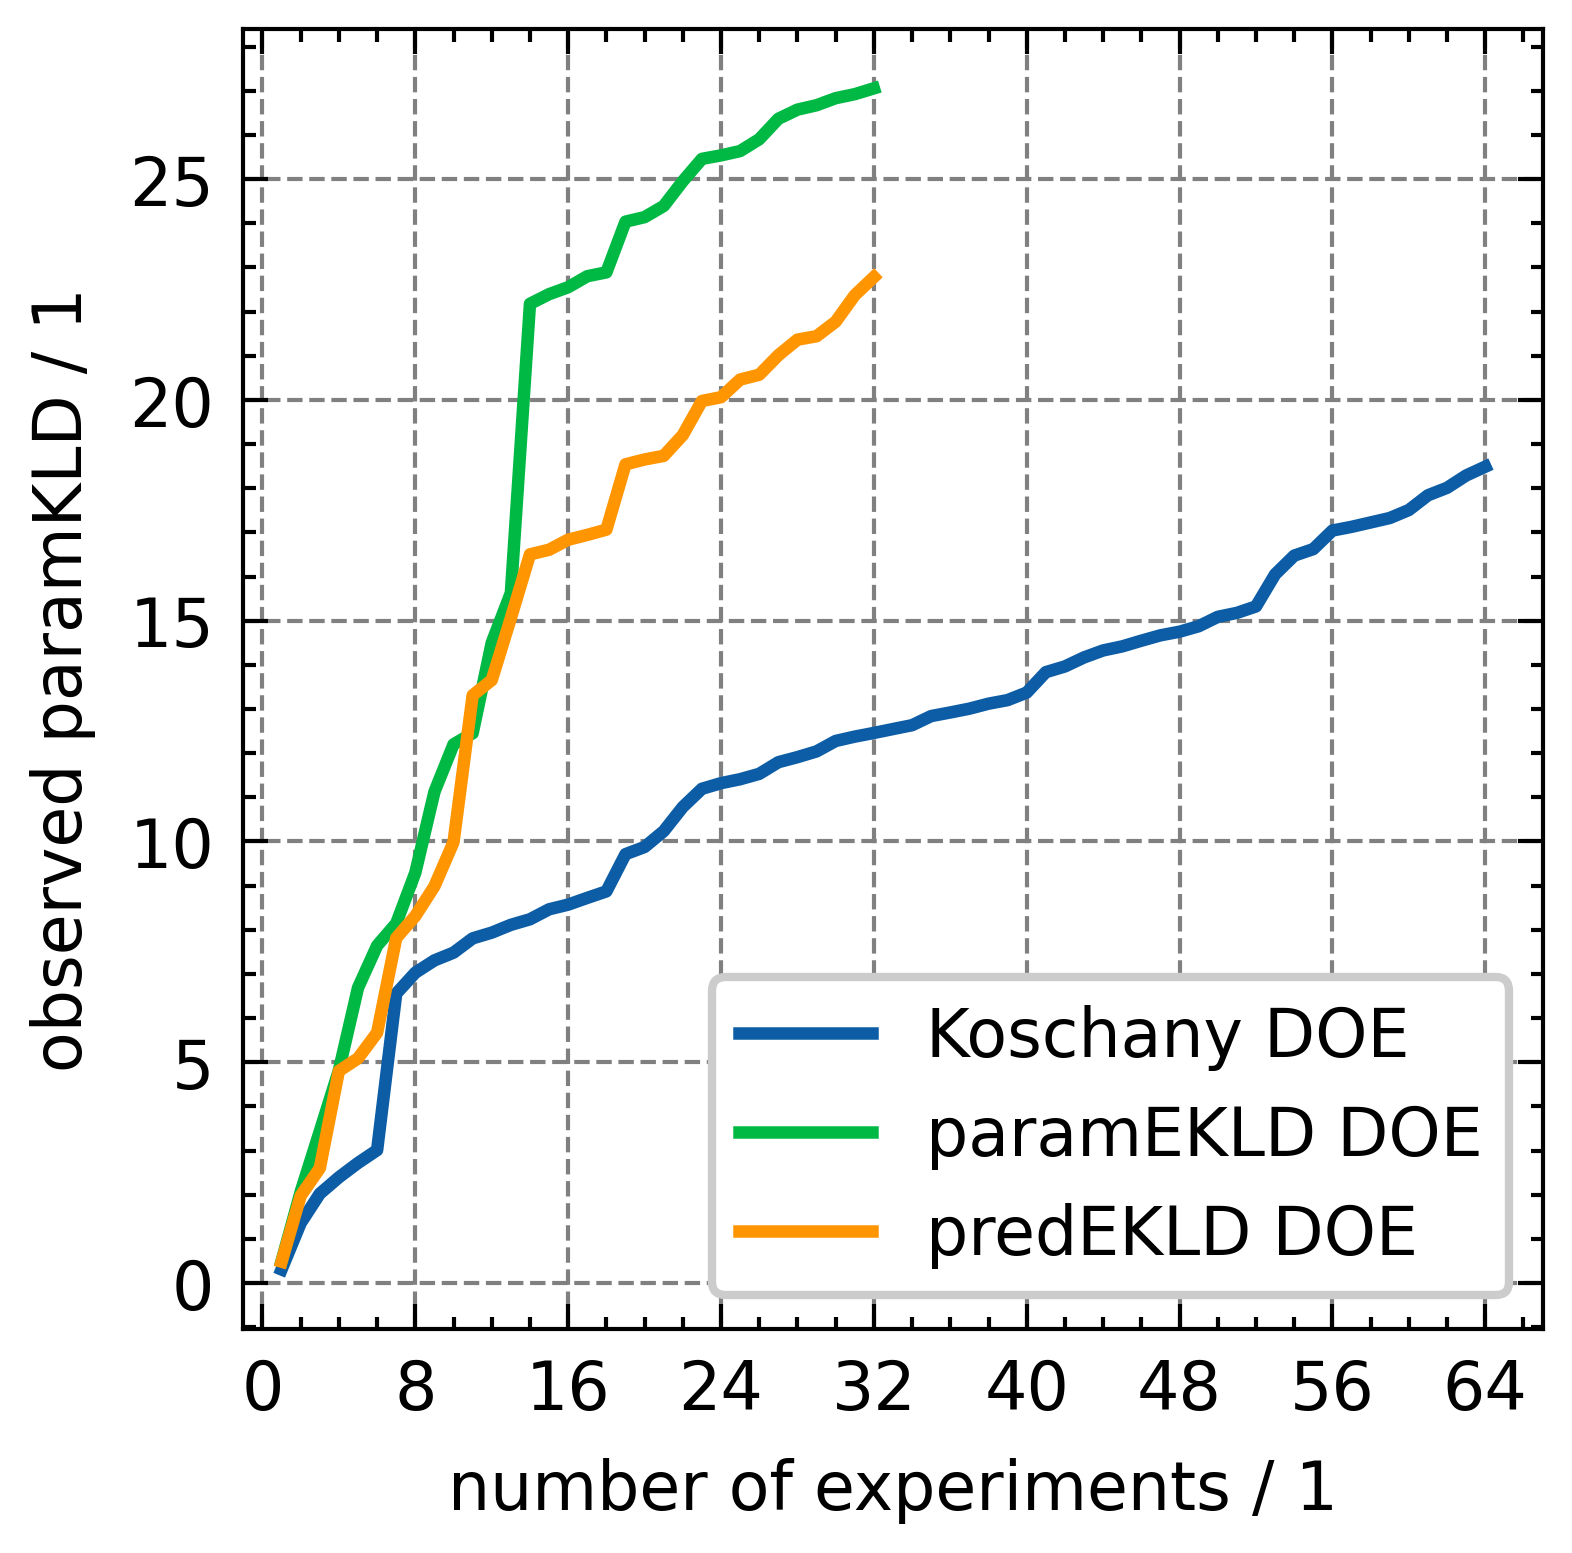

In [36]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel="observed paramKLD / 1",
    #ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0,8,16,24,32,40,48,56,64],
)
for i, ov_dict in enumerate(ov):
    ax.plot(
        np.arange(len(ov_dict["paramEKLDS"])) + 1,
        np.cumsum(ov_dict["paramEKLDS"]), 
        label=ov_dict["DOE"],
    )
    ax.legend()

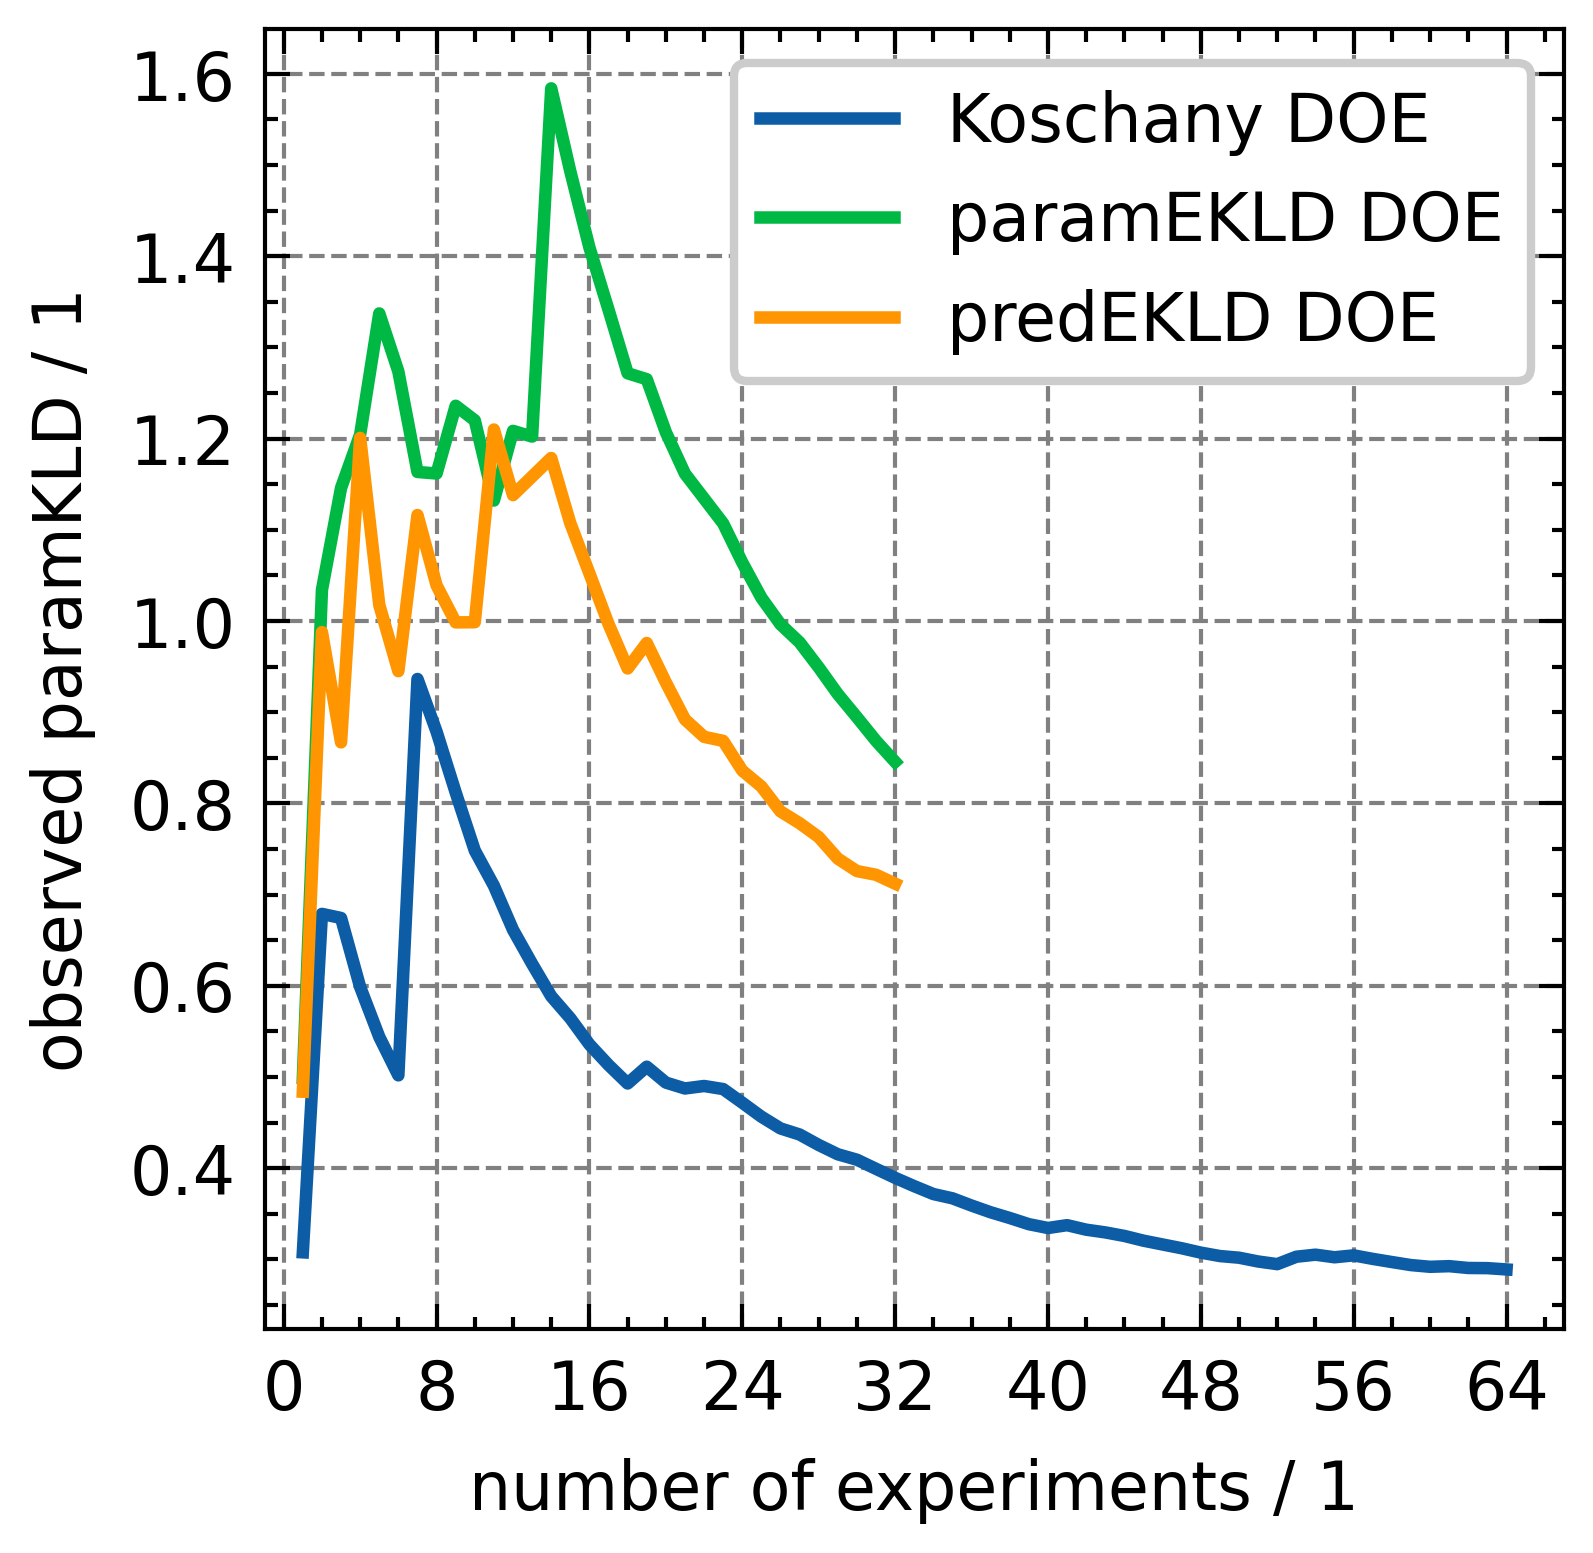

In [37]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel="observed paramKLD / 1",
    #ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0,8,16,24,32,40,48,56,64],
)
for i, ov_dict in enumerate(ov):
    ax.plot(
        x:=np.arange(len(ov_dict["paramEKLDS"])) + 1,
        np.cumsum(ov_dict["paramEKLDS"])/x, 
        label=ov_dict["DOE"],
    )
    ax.legend()

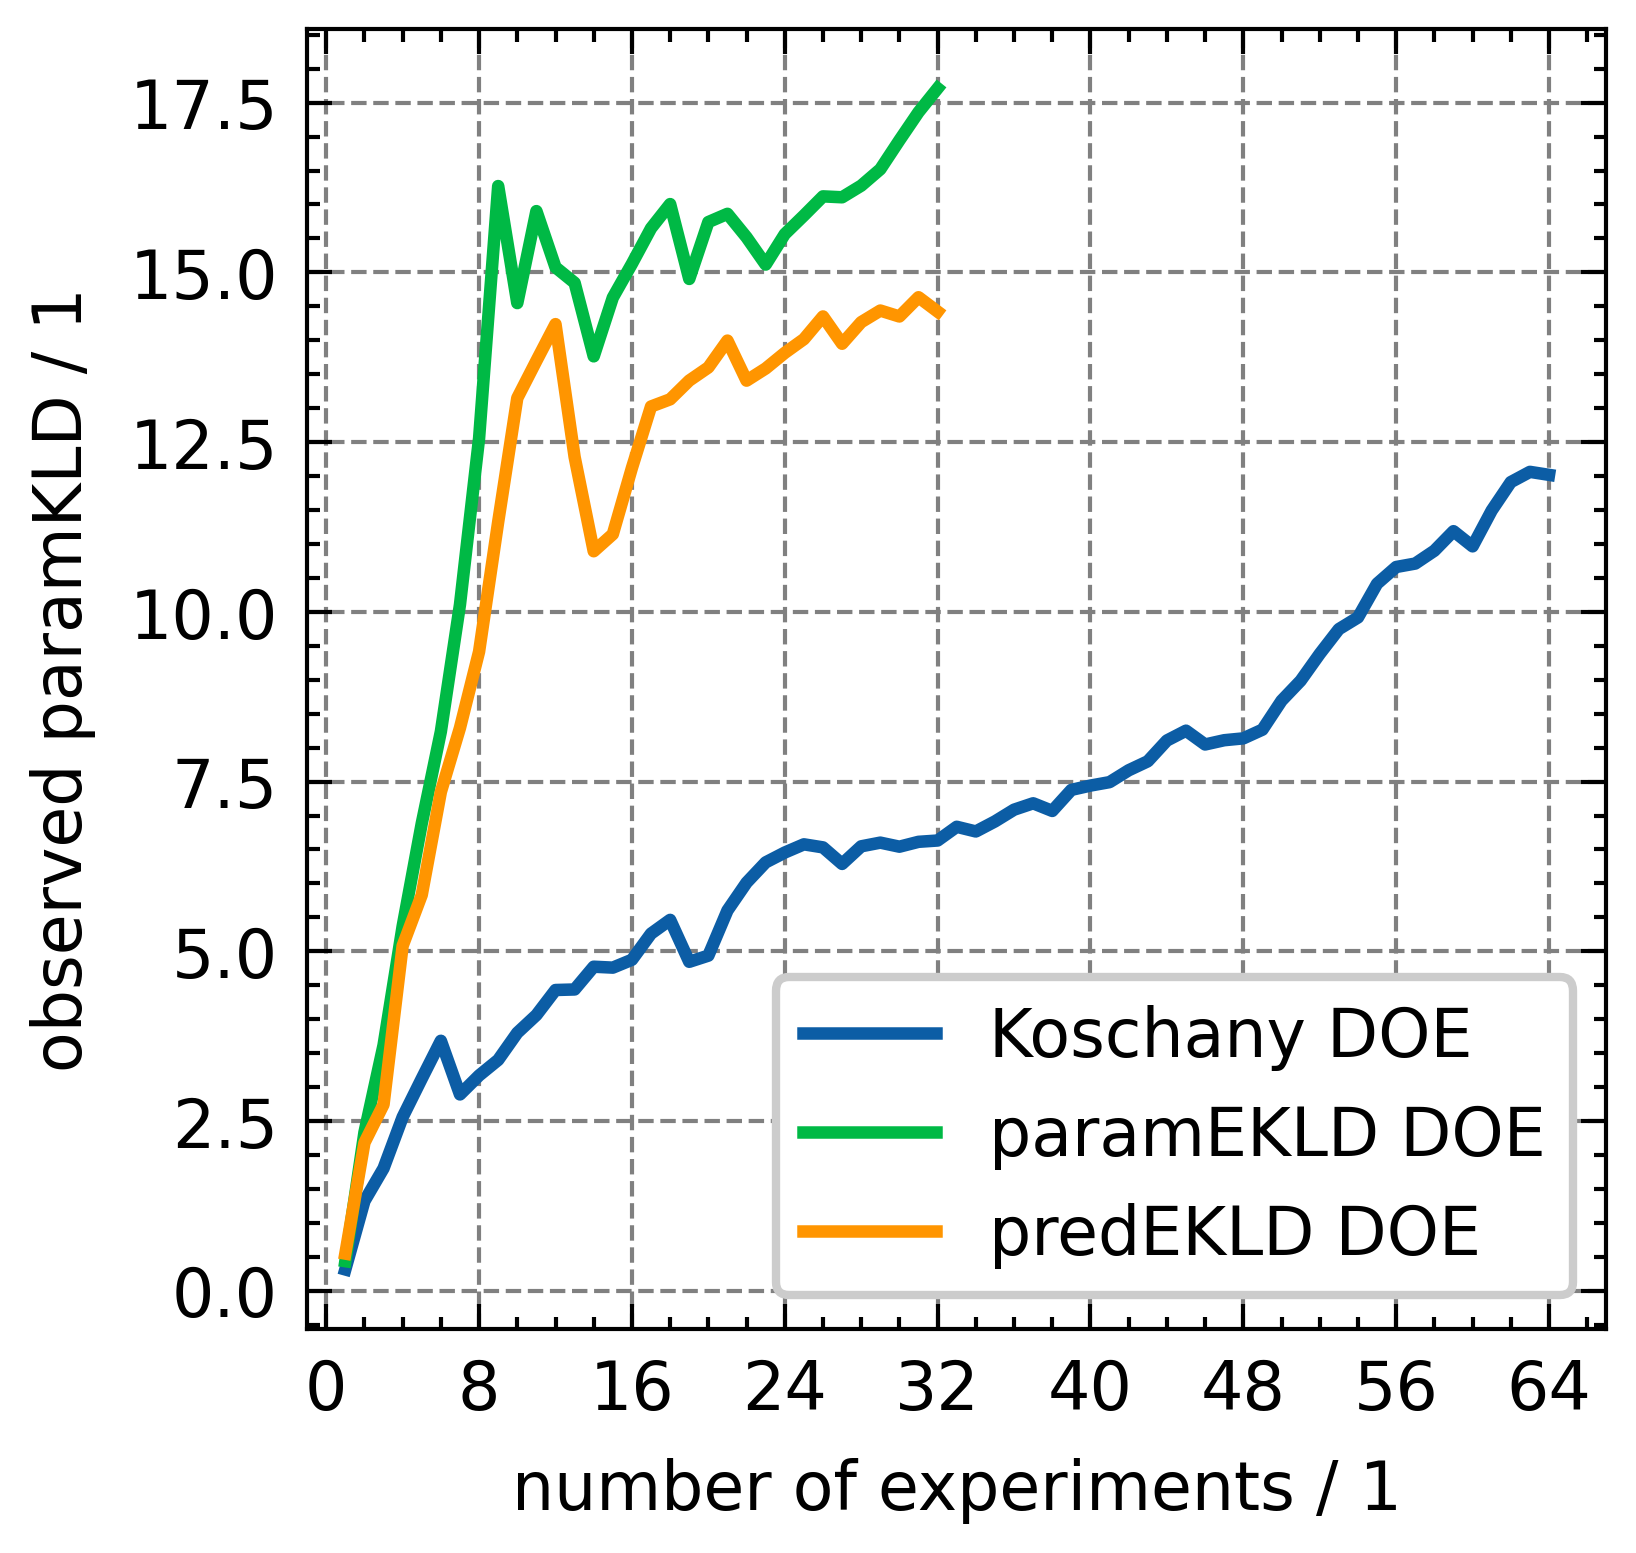

In [40]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel="observed paramKLD / 1",
    #ylim=(6e-7, 1e-4),
    xlim=(-1, 67),
    xticks=[0,8,16,24,32,40,48,56,64],
)
for i, ov_dict in enumerate(ov):
    ax.plot(
        np.arange(len(ov_dict["paramEKLDS_to_prior"])) + 1,
        ov_dict["paramEKLDS_to_prior"], 
        label=ov_dict["DOE"],
    )
    ax.legend()

### Posterior Predictive

In [38]:
def evaluate_conditions(proposal, idata, key="posterior"):
    """
    Evaluate posterior predictions over temperature range at given conditions.

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions
        idata: ArviZ InferenceData with posterior samples

    Returns:
        predictions: Array of shape (100, n_samples) with rate predictions
    """
    # Extract conditions from proposal
    p = jnp.array([[proposal[1]]])
    c2h = jnp.array([[proposal[2]]])
    c2m = jnp.array([[proposal[3]]])
    c2w = jnp.array([[proposal[4]]])
    c2i = jnp.array([[proposal[5]]])
    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, c2m, c2w, c2i)

    # Temperature range for evaluation
    T = jnp.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # Generate posterior predictions
    predictions = predict(idata, T, p_i, key=key, num_samples=1000)

    return predictions


def evaluate_true_model(proposal):
    """
    Compute true model predictions (for comparison with posterior).

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions

    Returns:
        true_rates: Array of shape (100, 1) with true rate predictions
    """
    # Extract conditions
    p = jnp.array([[proposal[1]]])
    c2h = jnp.array([[proposal[2]]])
    c2m = jnp.array([[proposal[3]]])
    c2w = jnp.array([[proposal[4]]])
    c2i = jnp.array([[proposal[5]]])

    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, c2m, c2w, c2i)

    # Temperature range
    T = jnp.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # True model prediction
    _, _, true_rates = generate_synthetic_data(
        T, p, c2h, c2m, c2w, c2i, rel_noise_std=0.0
    )

    return true_rates


def plot_predictions(fig, ax, posterior_preds, T_range):
    """
    Visualize posterior predictions vs true model with uncertainty.

    Args:
        proposal: Experimental conditions [T, p, c2h, f, c2i]
        posterior_preds: Posterior predictions (100, n_samples)
        true_preds: True model predictions (100, 1)
        T_range: Temperature values for x-axis
    """

    # Posterior mean
    ax.plot(
        T_range,
        posterior_preds.mean(axis=1),
        label="Posterior Mean",
        # color="blue",
    )

    # 95% credible interval
    ax.fill_between(
        T_range,
        np.percentile(posterior_preds, 2.5, axis=1),
        np.percentile(posterior_preds, 97.5, axis=1),
        alpha=0.3,
        # color="blue",
        label="95% HDI",
    )

    ax.legend(loc="upper left")
    return fig, ax

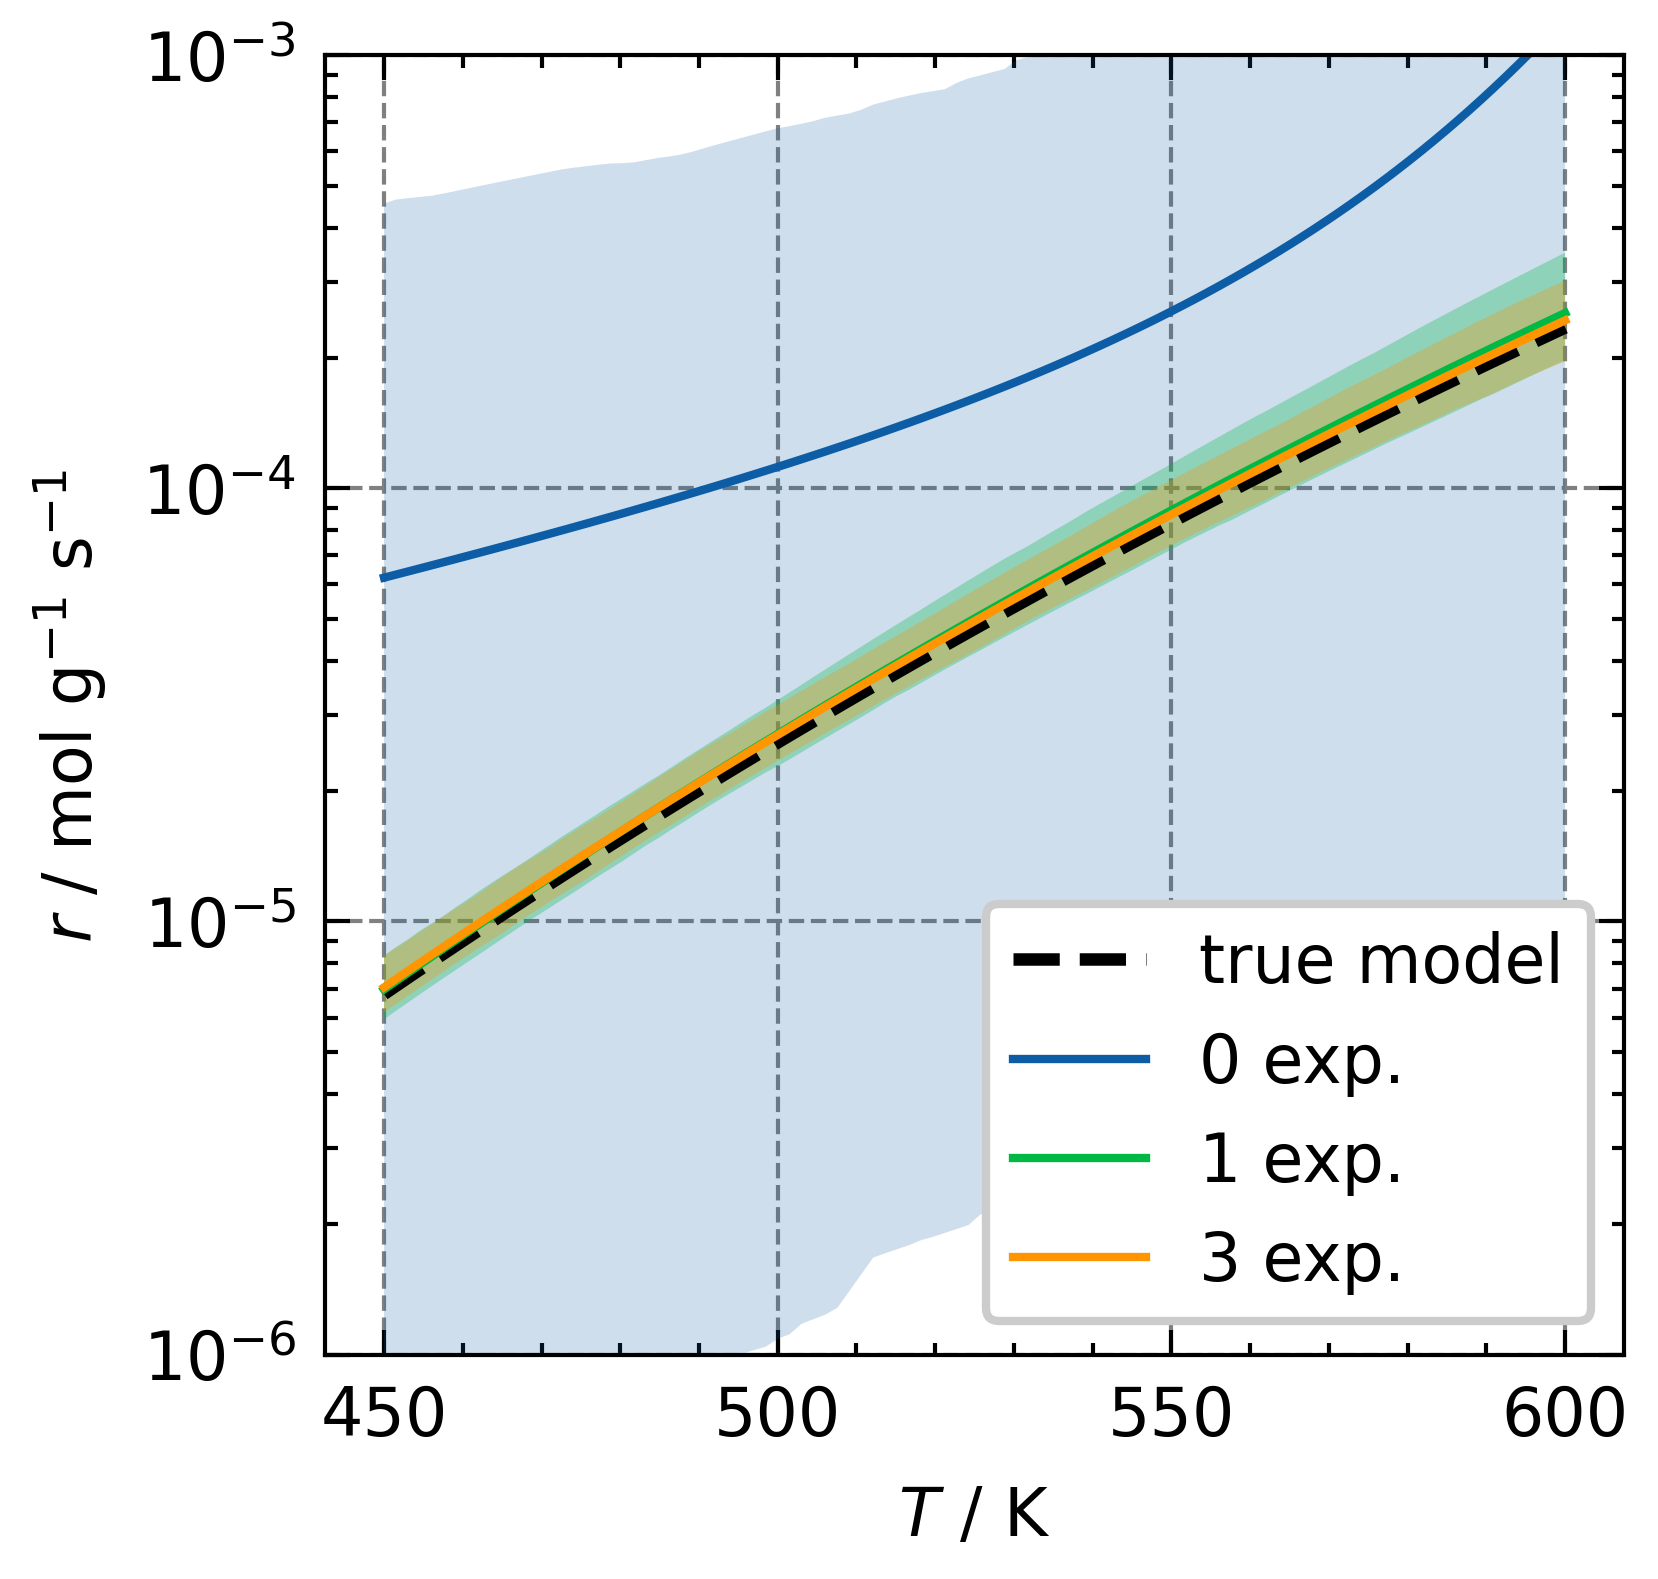

In [39]:
j = 4
T_range = np.linspace(450, 600, 100)
fig = ICIW_Plots.figure(layout="single_column")
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="$T$ / K",
    ylabel="$r$ / mol g$^{-1}$ s$^{-1}$",
    yscale="log",
    ylim=(1e-6, 1e-3),
    # xlim=(450, 600),
)
true_res = evaluate_true_model(
    proposal=ov[-1]["proposals"][j],
)
ax.plot(
    T_range,
    true_res.squeeze(),
    label="true model",
    color="black",
    linestyle="--",
    # linewidth=2,
)
# i=0
test_res = evaluate_conditions(
    proposal=ov[-1]["proposals"][j],
    idata=ov[-1]["idatas"][0],
    key="prior",
)
ax.plot(
    T_range,
    test_res.mean(axis=1),
    label="0 exp.",
    linewidth=1.0,
)
ax.fill_between(
    T_range,
    np.percentile(test_res, 2.5, axis=1),
    np.percentile(test_res, 97.5, axis=1),
    alpha=0.2,
)
# i=1
test_res = evaluate_conditions(
    proposal=ov[-1]["proposals"][j],
    idata=ov[-1]["idatas"][1],
    key="posterior",
)
ax.plot(
    T_range,
    test_res.mean(axis=1),
    label="1 exp.",
    linewidth=1.0,
)
ax.fill_between(
    T_range,
    np.percentile(test_res, 2.5, axis=1),
    np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
)
# i=3
test_res = evaluate_conditions(
    proposal=ov[-1]["proposals"][j],
    idata=ov[-1]["idatas"][3],
    key="posterior",
)
ax.plot(
    T_range,
    test_res.mean(axis=1),
    label="3 exp.",
    linewidth=1.0,
    # color="firebrick",
)
ax.fill_between(
    T_range,
    np.percentile(test_res, 2.5, axis=1),
    np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    # facecolor="firebrick",
)
plt.legend(loc="lower right", frameon=True)
plt.savefig("B_035_Predictions.png", dpi=600, bbox_inches="tight")

### Parameter identified

In [ ]:
from ipywidgets import interact, Dropdown
keydict = {
    "k0": "k0",
    "Ea_k": "EA",
    "A_oh": "A_OH",
    "dH_oh": "H_OH",
    "A_h2": "A_H2",
    "dH_h2": "H_H2",
    "A_mix": "A_mix",
    "dH_mix": "H_mix",
}

@interact(
    key=Dropdown(
        options=keydict.keys(),
        value="k0",
        description="Parameter:",
    ),
)
def plot_parameter_evolution(key):
    fig = ICIW_Plots.figure()
    ax = ICIW_Plots.make_square_ax(
        fig,
        ax_width=5.5 * ICIW_Plots.cm2inch,
        xlabel="number of experiments / 1",
        ylabel=f"{keydict[key]} / units",
        yscale="linear",
        # ylim=(6e-7, 1e-4),
        xlim=(-1, 67),
        xticks=[0,8,16,24,32,40,48,56,64],
    )
    for i, ov_dict in enumerate(ov):
        param_samples = []
        for idata in ov_dict["idatas"]:
            samples = idata.posterior[key].values.flatten()
            param_samples.append(samples)
        param_samples = np.array(param_samples)
        ax.axhline(
            y=TRUE_PARAMS[keydict[key]],
            color="gray",
            linestyle="dashed",
            zorder=0,
        )
        if ov_dict["DOE"] == "Koschany DOE":
            ax.hlines(
                np.median(param_samples, axis=1)[-1],
                xmin=-1,
                xmax=64,
                label=ov_dict["DOE"],
                ls="--",
                color=colors[i],
            )
            ax.fill_between(
                np.arange(-1,len(param_samples) + 1),
                np.quantile(param_samples, 0.025, axis=1)[-1],
                np.quantile(param_samples, 0.975, axis=1)[-1],
                alpha=0.2,
                #ls="--",
                facecolor=colors[i],
                # edgecolor="gray",
            )
            continue
        ax.plot(
            np.arange(1, len(param_samples) + 1),
            np.median(param_samples, axis=1),
            label=ov_dict["DOE"],
            color=plt.rcParams['axes.prop_cycle'].by_key()['color'][i],
        )
        ax.fill_between(
            np.arange(1, len(param_samples) + 1),
            np.quantile(param_samples, 0.025, axis=1),
            np.quantile(param_samples, 0.975, axis=1),
            alpha=0.2,
            facecolor=plt.rcParams['axes.prop_cycle'].by_key()['color'][i],
        )
        ax.legend(frameon=True)
    plt.show()

interactive(children=(Dropdown(description='Parameter:', options=('k0', 'Ea_k', 'A_oh', 'dH_oh', 'A_h2', 'dH_h…